In [1]:
from typing import TypedDict
from langgraph.graph import StateGraph,START,END

In [2]:
class AnswerState(TypedDict):
    attempts:int
    quality:str

In [4]:
state:AnswerState={
    "attempts":0,
    "quality":"poor"
}

In [5]:
def generate(state:AnswerState):
    return {"attempts":state["attempts"]+1}


In [7]:
def check(state:AnswerState):
    if state['attempts']>=3:
        return {"quality":'good'}
    else:
        return {"quality":"poor"}

In [8]:
def route_answer(state:AnswerState):
    if state['quality']=='good':
        return 'finish'
    else:
        return 'retry'

In [11]:
builder=StateGraph(AnswerState)
builder.add_node('generate',generate)
builder.add_node('check',check)


In [13]:
builder.add_edge(START,'generate')
builder.add_edge('generate','check')
builder.add_conditional_edges('check',route_answer,{
    "retry":'generate',"finish":END
})

In [23]:
graph=builder.compile()
result=graph.invoke( {"attempts": 1,
    "quality": "poor"}, config={"recursion_limit": 10})
print(result)

{'attempts': 3, 'quality': 'good'}


In [24]:

from typing import TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.types import Command


# 1. Define state
class AnswerState(TypedDict):
    attempts: int
    quality: str


# 2. Generate node
def generate(state: AnswerState):
    print("Generating answer...")

    return {
        "attempts": state["attempts"] + 1
    }


# 3. Check node using Command
def check(state: AnswerState):

    print("Checking answer...")

    if state["attempts"] >= 3:

        return Command(
            update={"quality": "good"},
            goto=END
        )

    else:

        return Command(
            update={"quality": "poor"},
            goto="generate"
        )


# 4. Create graph
builder = StateGraph(AnswerState)

builder.add_node("generate", generate)
builder.add_node("check", check)


# 5. Connect graph
builder.add_edge(START, "generate")
builder.add_edge("generate", "check")


# 6. Compile
graph = builder.compile()


# 7. Invoke
result = graph.invoke({
    "attempts": 0,
    "quality": "poor"
})

print(result)


Generating answer...
Checking answer...
Generating answer...
Checking answer...
Generating answer...
Checking answer...
{'attempts': 3, 'quality': 'good'}


In [38]:
from typing import TypedDict
from langgraph.graph import StateGraph,START,END
from langgraph.types import Command

In [39]:
class AnswerState(TypedDict):
    attempts:int
    quality:str

In [40]:
state:AnswerState={
    "attempts":0,
    "quality":"poor"
}

In [41]:
def generate(state:AnswerState):
    return {"attempts":state["attempts"]+1}

In [42]:
def check(state:AnswerState):
    if state['attempts']>=3:
        return  Command(
            update={"quality": "good"},
            goto=END
        )
    else:
        return Command(
            update={"quality": "poor"},
            goto='generate'
        )
    

In [43]:
builder=StateGraph(AnswerState)
builder.add_node('generate',generate)
builder.add_node('check',check)

In [44]:
builder.add_edge(START,'generate')
builder.add_edge('generate','check')

In [45]:
graph=builder.compile()
result=graph.invoke({
    "attempts":1,"quality":"poor"
})
print(
    result
)

{'attempts': 3, 'quality': 'good'}


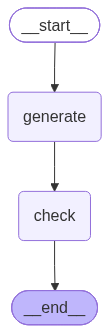

In [47]:
from IPython.display import Image,display
display(Image(graph.get_graph().draw_mermaid_png()))